# Tugas 05 - Bagian B: Transfer Learning (Oxford-IIIT Pet)

ResNet-18, 10 kelas. Protokol sama di semua kondisi: 224x224, norm ImageNet, batch 32,
AdamW (wd 1e-2), CrossEntropyLoss, early stopping (patience 4), seed 42.

| Kode | Strategi |
|------|----------|
| B1 | From scratch |
| B2 | Feature extraction (backbone beku, latih fc) |
| B3 | Fine-tune layer4 + fc, differential LR |
| B4 | B3 tanpa augmentasi (dibanding B3) |
| B5 | MobileNetV3-Small (bonus) |

## 1. Setup dan reproduksibilitas

In [1]:
import json
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader
from torchvision import models, transforms
from torchvision.datasets import OxfordIIITPet

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## 2. Dataset: subset 10 kelas, split stratified 70/15/15

In [2]:
# 5 kucing + 5 anjing (nama kelas mengikuti torchvision OxfordIIITPet)
selected = [
    "Bengal", "Birman", "Bombay", "British Shorthair", "Egyptian Mau",
    "Beagle", "Boxer", "Chihuahua", "Pug", "Pomeranian",
]

imagenet = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

aug_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    imagenet,
])

plain_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    imagenet,
])

In [3]:
trainval = OxfordIIITPet(root="data", split="trainval", download=True)
testset = OxfordIIITPet(root="data", split="test", download=True)

orig_to_new = {trainval.classes.index(name): i for i, name in enumerate(selected)}

# gabung kedua split lalu split ulang 70/15/15 sendiri (~2000 citra)
all_labels = list(trainval._labels) + list(testset._labels)
n_trainval = len(trainval._labels)

idx = [i for i, lbl in enumerate(all_labels) if lbl in orig_to_new]
labels = [orig_to_new[all_labels[i]] for i in idx]

train_idx, temp_idx, _, temp_labels = train_test_split(
    idx, labels, train_size=0.70, stratify=labels, random_state=SEED
)
val_idx, test_idx = train_test_split(
    temp_idx, train_size=0.50, stratify=temp_labels, random_state=SEED
)

print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}")

train=1381  val=296  test=296


In [4]:
class PetSubset(torch.utils.data.Dataset):
    def __init__(self, indices, transform):
        self.trainval = OxfordIIITPet(root="data", split="trainval", transform=transform)
        self.test = OxfordIIITPet(root="data", split="test", transform=transform)
        self.indices = indices

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        g = self.indices[i]
        if g < n_trainval:
            img, label = self.trainval[g]
        else:
            img, label = self.test[g - n_trainval]
        return img, orig_to_new[label]


def make_loaders(train_aug):
    train_tf = aug_transform if train_aug else plain_transform
    train_dl = DataLoader(PetSubset(train_idx, train_tf), batch_size=32, shuffle=True, num_workers=0)
    val_dl = DataLoader(PetSubset(val_idx, plain_transform), batch_size=32, num_workers=0)
    test_dl = DataLoader(PetSubset(test_idx, plain_transform), batch_size=32, num_workers=0)
    return train_dl, val_dl, test_dl

## 3. Builder model untuk tiap kondisi

In [5]:
def count_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def build_resnet(strategy):
    weights = None if strategy == "scratch" else models.ResNet18_Weights.IMAGENET1K_V1
    model = models.resnet18(weights=weights)
    model.fc = nn.Linear(model.fc.in_features, 10)

    if strategy == "feature":
        for p in model.parameters():
            p.requires_grad = False
        for p in model.fc.parameters():
            p.requires_grad = True
    elif strategy == "finetune":
        for p in model.parameters():
            p.requires_grad = False
        for p in model.layer4.parameters():
            p.requires_grad = True
        for p in model.fc.parameters():
            p.requires_grad = True

    n = count_trainable(model)
    print(f"trainable params: {n:,}")
    if strategy == "feature":
        assert n == 5130, n

    if strategy == "feature":
        opt = torch.optim.AdamW(model.fc.parameters(), lr=1e-3, weight_decay=1e-2)
    elif strategy == "finetune":
        opt = torch.optim.AdamW([
            {"params": model.layer4.parameters(), "lr": 1e-4},
            {"params": model.fc.parameters(), "lr": 1e-3},
        ], weight_decay=1e-2)
    else:
        opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)

    return model.to(device), opt


def freeze_bn(model):
    # BatchNorm beku harus tetap eval saat training agar running stats tak bergeser
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d) and not m.weight.requires_grad:
            m.eval()

## 4. Loop pelatihan dengan early stopping

In [6]:
criterion = nn.CrossEntropyLoss()


def run_epoch(model, loader, opt=None):
    training = opt is not None
    model.train(training)
    if training:
        freeze_bn(model)
    total_loss, correct, n = 0.0, 0, 0
    preds, targets = [], []

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.set_grad_enabled(training):
            out = model(x)
            loss = criterion(out, y)
            if training:
                opt.zero_grad()
                loss.backward()
                opt.step()
        total_loss += loss.item() * x.size(0)
        pred = out.argmax(1)
        correct += (pred == y).sum().item()
        n += x.size(0)
        preds += pred.cpu().tolist()
        targets += y.cpu().tolist()

    return total_loss / n, correct / n, preds, targets


def train(model, opt, loaders, max_epochs=20, patience=4):
    train_dl, val_dl, _ = loaders
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_loss, best_state, best_epoch, waited = float("inf"), None, 0, 0
    best_train_acc, best_val_acc = 0.0, 0.0
    start = time.time()

    for epoch in range(1, max_epochs + 1):
        tr_loss, tr_acc, _, _ = run_epoch(model, train_dl, opt)
        val_loss, val_acc, _, _ = run_epoch(model, val_dl)
        history["train_loss"].append(tr_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(val_acc)
        print(f"epoch {epoch:2d} | train {tr_loss:.3f}/{tr_acc:.2f} | val {val_loss:.3f}/{val_acc:.2f}")

        if val_loss < best_loss - 1e-4:
            best_loss, best_epoch, waited = val_loss, epoch, 0
            best_train_acc, best_val_acc = tr_acc, val_acc
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            waited += 1
            if waited >= patience:
                print(f"early stop di epoch {epoch}")
                break

    model.load_state_dict(best_state)
    return history, best_epoch, best_train_acc, best_val_acc, time.time() - start

## 5. Runner satu eksperimen

In [7]:
results = []
curves = {}


def run_experiment(code, strategy, lr_note, augment=True):
    print(f"\n===== {code}: {strategy} (augment={augment}) =====")
    torch.manual_seed(SEED)
    model, opt = build_resnet(strategy)
    loaders = make_loaders(train_aug=augment)

    history, best_epoch, train_acc, val_acc, elapsed = train(model, opt, loaders)
    _, test_acc, preds, targets = run_epoch(model, loaders[2])
    macro_f1 = f1_score(targets, preds, average="macro")

    curves[code] = history
    results.append({
        "code": code,
        "strategy": strategy,
        "augment": augment,
        "trainable_params": count_trainable(model),
        "learning_rate": lr_note,
        "epochs_to_converge": best_epoch,
        "train_time_s": round(elapsed, 1),
        "train_accuracy": round(train_acc, 4),
        "val_accuracy": round(val_acc, 4),
        "test_accuracy": round(test_acc, 4),
        "test_macro_f1": round(macro_f1, 4),
    })
    print(f"val_acc={val_acc:.3f}  test_macroF1={macro_f1:.3f}")
    return model

## 6. Eksperimen B1-B4

In [8]:
run_experiment("B1", "scratch", "1e-3 (semua)")
b2_model = run_experiment("B2", "feature", "1e-3 (fc)")
best_model = run_experiment("B3", "finetune", "layer4 1e-4 / fc 1e-3")

# B4: B3 tanpa augmentasi, dibandingkan dengan B3 (dengan augmentasi) di atas
run_experiment("B4_noaug", "finetune", "layer4 1e-4 / fc 1e-3", augment=False)


===== B1: scratch (augment=True) =====


trainable params: 11,181,642


epoch  1 | train 2.294/0.19 | val 2.052/0.29


epoch  2 | train 2.049/0.29 | val 2.288/0.23


epoch  3 | train 1.862/0.35 | val 2.665/0.28


...

epoch  5 | train 0.014/1.00 | val 0.141/0.96


epoch  6 | train 0.009/1.00 | val 0.138/0.97


epoch  7 | train 0.021/0.99 | val 0.152/0.94
early stop di epoch 7


val_acc=0.963  test_macroF1=0.956


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

## 7. B5 (bonus): MobileNetV3-Small

In [9]:
def run_mobilenet():
    print("\n===== B5: MobileNetV3-Small finetune =====")
    torch.manual_seed(SEED)
    weights = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1
    model = models.mobilenet_v3_small(weights=weights)
    model.classifier[3] = nn.Linear(model.classifier[3].in_features, 10)

    for p in model.parameters():
        p.requires_grad = False
    for p in model.features[-3:].parameters():
        p.requires_grad = True
    for p in model.classifier.parameters():
        p.requires_grad = True

    opt = torch.optim.AdamW([
        {"params": model.features[-3:].parameters(), "lr": 1e-4},
        {"params": model.classifier.parameters(), "lr": 1e-3},
    ], weight_decay=1e-2)
    model = model.to(device)
    loaders = make_loaders(train_aug=True)

    history, best_epoch, train_acc, val_acc, elapsed = train(model, opt, loaders)
    _, test_acc, preds, targets = run_epoch(model, loaders[2])
    macro_f1 = f1_score(targets, preds, average="macro")

    curves["B5"] = history
    results.append({
        "code": "B5",
        "strategy": "mobilenetv3_finetune",
        "augment": True,
        "trainable_params": count_trainable(model),
        "learning_rate": "features 1e-4 / classifier 1e-3",
        "epochs_to_converge": best_epoch,
        "train_time_s": round(elapsed, 1),
        "train_accuracy": round(train_acc, 4),
        "val_accuracy": round(val_acc, 4),
        "test_accuracy": round(test_acc, 4),
        "test_macro_f1": round(macro_f1, 4),
    })
    print(f"val_acc={val_acc:.3f}  test_macroF1={macro_f1:.3f}")


run_mobilenet()


===== B5: MobileNetV3-Small finetune =====


epoch  1 | train 0.759/0.77 | val 0.250/0.93


epoch  2 | train 0.210/0.93 | val 0.262/0.92


epoch  3 | train 0.164/0.95 | val 0.227/0.93


epoch  4 | train 0.134/0.96 | val 0.228/0.92


...

epoch  7 | train 0.060/0.98 | val 0.291/0.91


epoch  8 | train 0.040/0.99 | val 0.245/0.93


epoch  9 | train 0.040/0.99 | val 0.315/0.92


epoch 10 | train 0.034/0.99 | val 0.308/0.91
early stop di epoch 10


val_acc=0.922  test_macroF1=0.955


## 8. Tabel konsolidasi + simpan log mentah (CSV/JSON)

In [10]:
summary = pd.DataFrame(results)
summary.to_csv("metrics.csv", index=False)
with open("metrics.json", "w") as f:
    json.dump({"results": results, "curves": curves}, f, indent=2)
summary

,code,strategy,augment,trainable_params,learning_rate,epochs_to_converge,train_time_s,train_accuracy,val_accuracy,test_accuracy,test_macro_f1
0,B1,scratch,True,11181642,1e-3 (semua),1,69.7,0.1948,0.2872,0.2736,0.2016
1,B2,feature,True,5130,1e-3 (fc),20,225.7,0.9899,0.9628,0.9595,0.9594
2,B3,finetune,True,8398858,layer4 1e-4 / fc 1e-3,6,117.0,0.9928,0.9595,0.9527,0.9518
3,B4_noaug,finetune,False,8398858,layer4 1e-4 / fc 1e-3,3,63.7,0.9971,0.9628,0.9561,0.9556
4,B5,mobilenetv3_finetune,True,1245738,features 1e-4 / classifier 1e-3,6,120.4,0.9841,0.9223,0.9561,0.9551


## 9. Kurva training vs validation loss (B1, B2, B3)

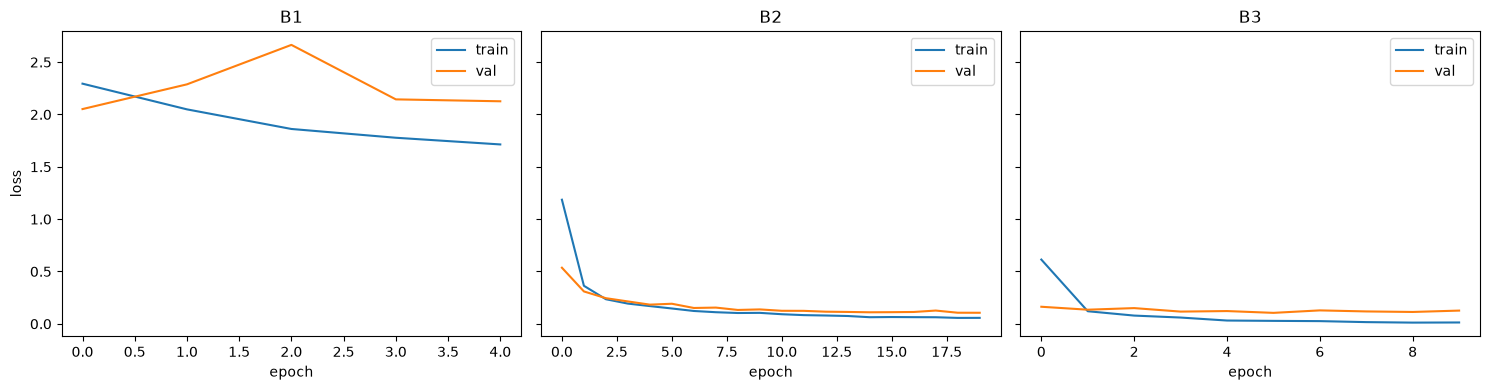

In [11]:
import os
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, code in zip(axes, ["B1", "B2", "B3"]):
    h = curves[code]
    ax.plot(h["train_loss"], label="train")
    ax.plot(h["val_loss"], label="val")
    ax.set_title(code)
    ax.set_xlabel("epoch")
    ax.legend()
axes[0].set_ylabel("loss")
plt.tight_layout()
os.makedirs("outputs", exist_ok=True)
plt.savefig("outputs/loss_curves.png", dpi=200, bbox_inches="tight")
plt.show()

## 10. Failure analysis: sampel salah prediksi dari model terbaik (B2)

true: Beagle | pred: Boxer | conf: 0.840
true: Egyptian Mau | pred: Bengal | conf: 0.582
true: Egyptian Mau | pred: Bengal | conf: 0.733
true: Bengal | pred: Egyptian Mau | conf: 0.548
true: Pug | pred: Bombay | conf: 0.602
true: British Shorthair | pred: Bengal | conf: 0.891
true: Egyptian Mau | pred: Bengal | conf: 0.606
true: Bengal | pred: Egyptian Mau | conf: 0.622


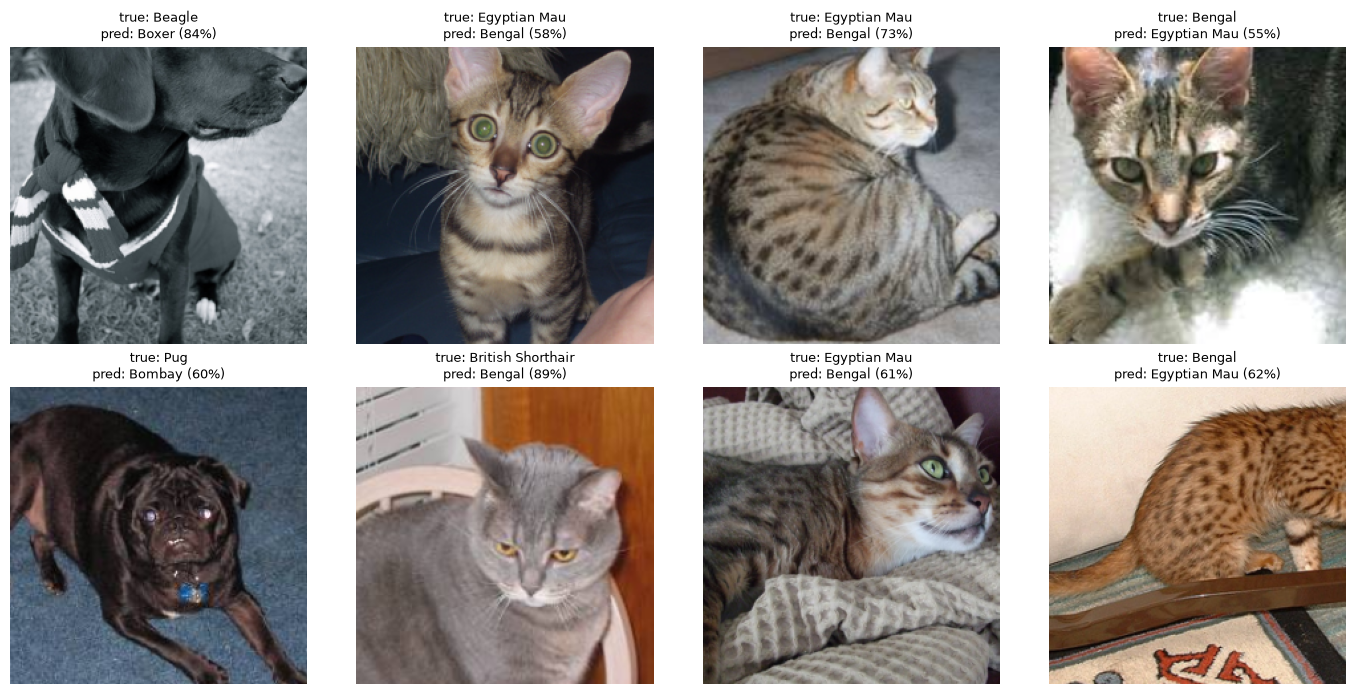

In [12]:
_, _, test_loader = make_loaders(train_aug=False)
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

b2_model.eval()
wrong = []
with torch.no_grad():
    for x, y in test_loader:
        probs = b2_model(x.to(device)).softmax(1).cpu()
        conf, pred = probs.max(1)
        for i in range(len(y)):
            if pred[i] != y[i]:
                wrong.append((x[i], y[i].item(), pred[i].item(), conf[i].item()))
        if len(wrong) >= 8:
            break

for _, true, pred, conf in wrong[:8]:
    print(f"true: {selected[true]} | pred: {selected[pred]} | conf: {conf:.3f}")

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (img, true, pred, conf) in zip(axes.ravel(), wrong[:8]):
    ax.imshow((img * std + mean).permute(1, 2, 0).clamp(0, 1))
    ax.set_title(f"true: {selected[true]}\npred: {selected[pred]} ({conf:.0%})", fontsize=9)
    ax.axis("off")
plt.tight_layout()
os.makedirs("outputs", exist_ok=True)
plt.savefig("outputs/failure_analysis.png", dpi=200, bbox_inches="tight")
plt.show()